In [1]:

# Bibliotecas para análise de dados

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [2]:

import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:

print("Linhas e colunas:", df.shape)


Linhas e colunas: (284807, 31)


In [4]:
df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [5]:
df["Class"].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


In [6]:
df["Amount"].describe()

,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000


In [7]:
import numpy as np

df["Amount_log"] = np.log1p(df["Amount"])

df[["Amount", "Amount_log"]].head()

,Amount,Amount_log
0,149.62,5.014760
1,2.69,1.305626
2,378.66,5.939276
3,123.50,4.824306
4,69.99,4.262539


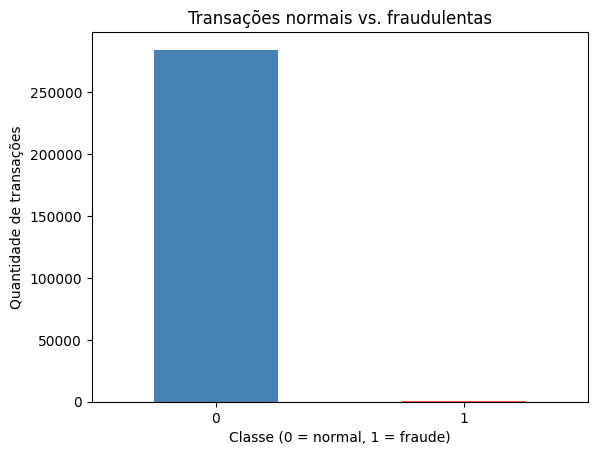

In [8]:
import matplotlib.pyplot as plt

df["Class"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "tomato"]
)

plt.title("Transações normais vs. fraudulentas")
plt.xlabel("Classe (0 = normal, 1 = fraude)")
plt.ylabel("Quantidade de transações")
plt.xticks(rotation=0)
plt.show()

In [9]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Formato de X: (284807, 31)
Formato de y: (284807,)


In [10]:
X = df.drop(columns=["Class", "Amount", "Time"])
y = df["Class"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Colunas de X:", X.columns.tolist())

Formato de X: (284807, 29)
Formato de y: (284807,)
Colunas de X: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log']


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)
print("\nFraudes no treino:", y_train.sum())
print("Fraudes no teste:", y_test.sum())

Treino: (199364, 29)
Teste: (85443, 29)

Fraudes no treino: 344
Fraudes no teste: 148


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

modelo_lr.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [13]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = modelo_lr.predict(X_test)

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred, zero_division=0))

Matriz de confusão:
[[83374  1921]
 [   18   130]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     85295
           1       0.06      0.88      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.93      0.55     85443
weighted avg       1.00      0.98      0.99     85443



In [14]:
from sklearn.metrics import classification_report, confusion_matrix

probabilidades = modelo_lr.predict_proba(X_test)[:, 1]

y_pred_30 = (probabilidades >= 0.30).astype(int)

print("Matriz de confusão — limiar 0.30:")
print(confusion_matrix(y_test, y_pred_30))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_30, zero_division=0))

Matriz de confusão — limiar 0.30:
[[81111  4184]
 [   15   133]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     85295
           1       0.03      0.90      0.06       148

    accuracy                           0.95     85443
   macro avg       0.52      0.92      0.52     85443
weighted avg       1.00      0.95      0.97     85443



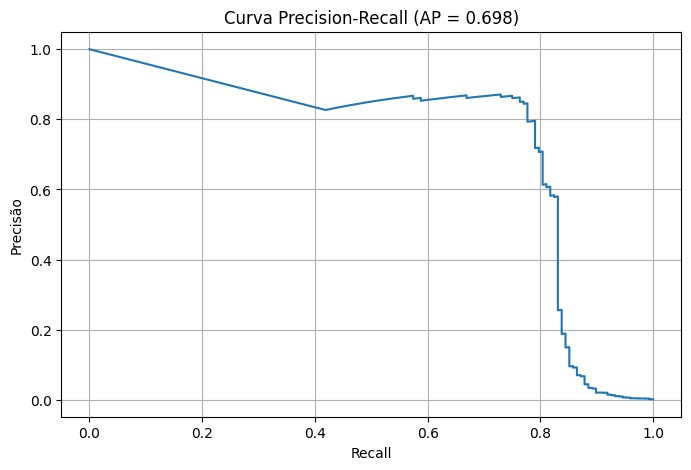

Average Precision (AP): 0.6978


In [15]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precisao, recall, limiares = precision_recall_curve(
    y_test, probabilidades
)

ap = average_precision_score(y_test, probabilidades)

plt.figure(figsize=(8, 5))
plt.plot(recall, precisao)
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title(f"Curva Precision-Recall (AP = {ap:.3f})")
plt.grid(True)
plt.show()

print(f"Average Precision (AP): {ap:.4f}")

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


In [17]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_rf = modelo_rf.predict(X_test)

print("Matriz de confusão — Random Forest:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Matriz de confusão — Random Forest:
[[85273    22]
 [   34   114]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.77      0.80       148

    accuracy                           1.00     85443
   macro avg       0.92      0.89      0.90     85443
weighted avg       1.00      1.00      1.00     85443



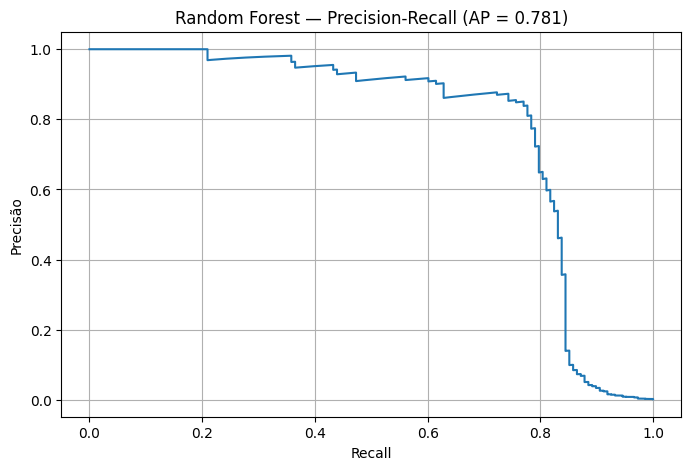

Average Precision do Random Forest: 0.7807


In [18]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

probabilidades_rf = modelo_rf.predict_proba(X_test)[:, 1]

precisao_rf, recall_rf, limiares_rf = precision_recall_curve(
    y_test, probabilidades_rf
)

ap_rf = average_precision_score(y_test, probabilidades_rf)

plt.figure(figsize=(8, 5))
plt.plot(recall_rf, precisao_rf)
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title(f"Random Forest — Precision-Recall (AP = {ap_rf:.3f})")
plt.grid(True)
plt.show()

print(f"Average Precision do Random Forest: {ap_rf:.4f}")

In [19]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

comparacao = pd.DataFrame({
    "Modelo": ["Regressão Logística", "Random Forest"],
    "Precisão": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf)
    ],
    "Average Precision": [
        average_precision_score(y_test, probabilidades),
        average_precision_score(y_test, probabilidades_rf)
    ]
})

comparacao.round(4)

,Modelo,Precisão,Recall,F1-score,Average Precision
0,Regressão Logística,0.0634,0.8784,0.1182,0.6978
1,Random Forest,0.8382,0.7703,0.8028,0.7807


Cinco variáveis mais importantes:
V10    0.159379
V14    0.140225
V4     0.121912
V12    0.105581
V11    0.092668
dtype: float64


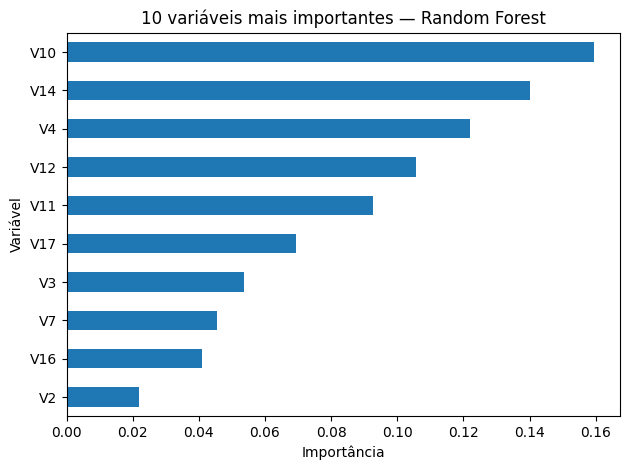

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Cinco variáveis mais importantes:")
print(importancias.head(5))

importancias.head(10).sort_values().plot(kind="barh")
plt.title("10 variáveis mais importantes — Random Forest")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()


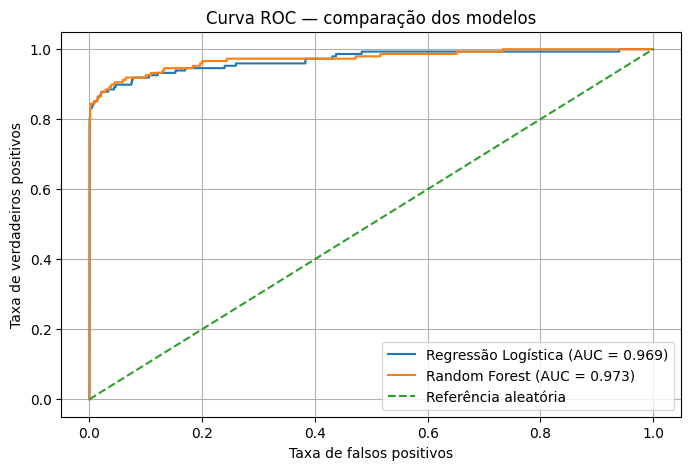

ROC-AUC — Regressão Logística: 0.9692
ROC-AUC — Random Forest: 0.9727


In [21]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

auc_lr = roc_auc_score(y_test, probabilidades)
auc_rf = roc_auc_score(y_test, probabilidades_rf)

fpr_lr, tpr_lr, _ = roc_curve(y_test, probabilidades)
fpr_rf, tpr_rf, _ = roc_curve(y_test, probabilidades_rf)

plt.figure(figsize=(8, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Regressão Logística (AUC = {auc_lr:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Referência aleatória")

plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC — comparação dos modelos")
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC — Regressão Logística: {auc_lr:.4f}")
print(f"ROC-AUC — Random Forest: {auc_rf:.4f}")


In [22]:
try:
    import xgboost as xgb
    print("XGBoost instalado:", xgb.__version__)
except ImportError:
    print("XGBoost não está instalado.")

XGBoost instalado: 3.4.1


In [23]:

from xgboost import XGBClassifier

modelo_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(X_train, y_train)

print("XGBoost treinado com sucesso!")


XGBoost treinado com sucesso!


In [24]:

from sklearn.metrics import classification_report, confusion_matrix

y_pred_xgb = modelo_xgb.predict(X_test)

print("Matriz de confusão — XGBoost:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))


Matriz de confusão — XGBoost:
[[85152   143]
 [   25   123]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.46      0.83      0.59       148

    accuracy                           1.00     85443
   macro avg       0.73      0.91      0.80     85443
weighted avg       1.00      1.00      1.00     85443



In [25]:

from sklearn.metrics import average_precision_score

probabilidades_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

ap_xgb = average_precision_score(y_test, probabilidades_xgb)

print(f"Average Precision do XGBoost: {ap_xgb:.4f}")


Average Precision do XGBoost: 0.7934


In [26]:

from sklearn.metrics import roc_auc_score

auc_xgb = roc_auc_score(y_test, probabilidades_xgb)

print(f"ROC-AUC — XGBoost: {auc_xgb:.4f}")


ROC-AUC — XGBoost: 0.9758


In [27]:
try:
    import shap
    print("SHAP instalado:", shap.__version__)
except ImportError:
    print("SHAP não está instalado.")

SHAP instalado: 0.54.1


In [28]:

import shap

# Selecionar uma amostra dos dados de teste
X_shap = X_test.sample(n=500, random_state=42)

# Criar o explicador do Random Forest
explainer = shap.TreeExplainer(modelo_rf)

# Calcular as contribuições das variáveis
shap_values = explainer.shap_values(X_shap)

print("Análise SHAP calculada com sucesso!")


Análise SHAP calculada com sucesso!


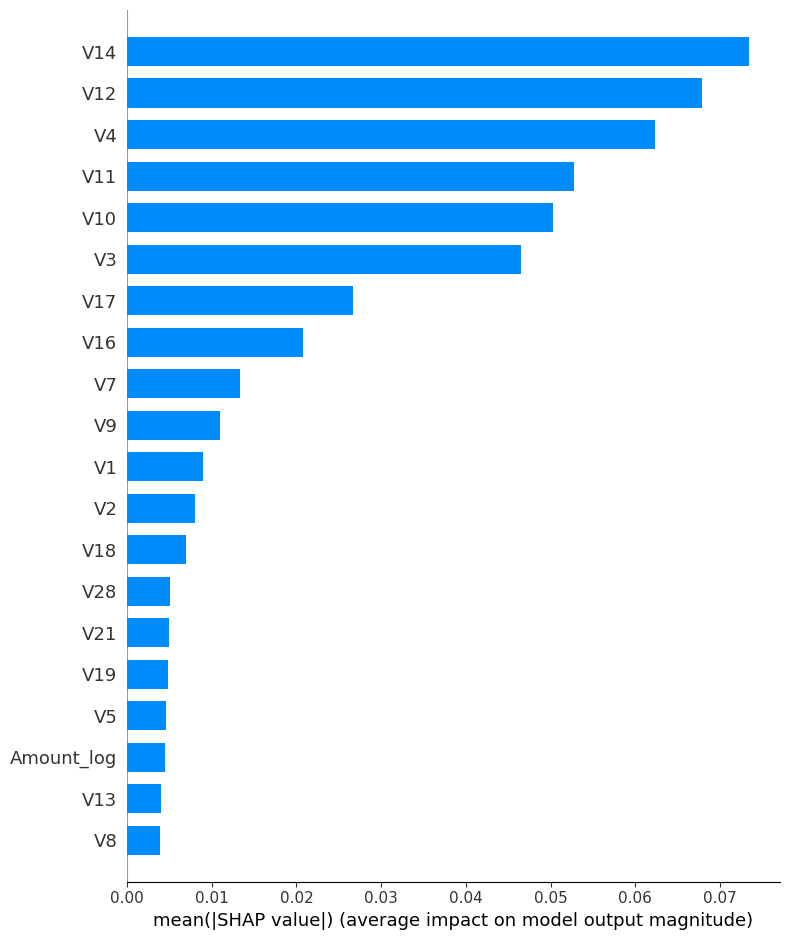

In [29]:
import numpy as np

# Selecionar os valores SHAP referentes à classe fraude (1)
if isinstance(shap_values, list):
    shap_fraude = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_fraude = shap_values[:, :, 1]
else:
    shap_fraude = shap_values

# Gráfico de importância global
shap.summary_plot(
    shap_fraude,
    X_shap,
    plot_type="bar"
)

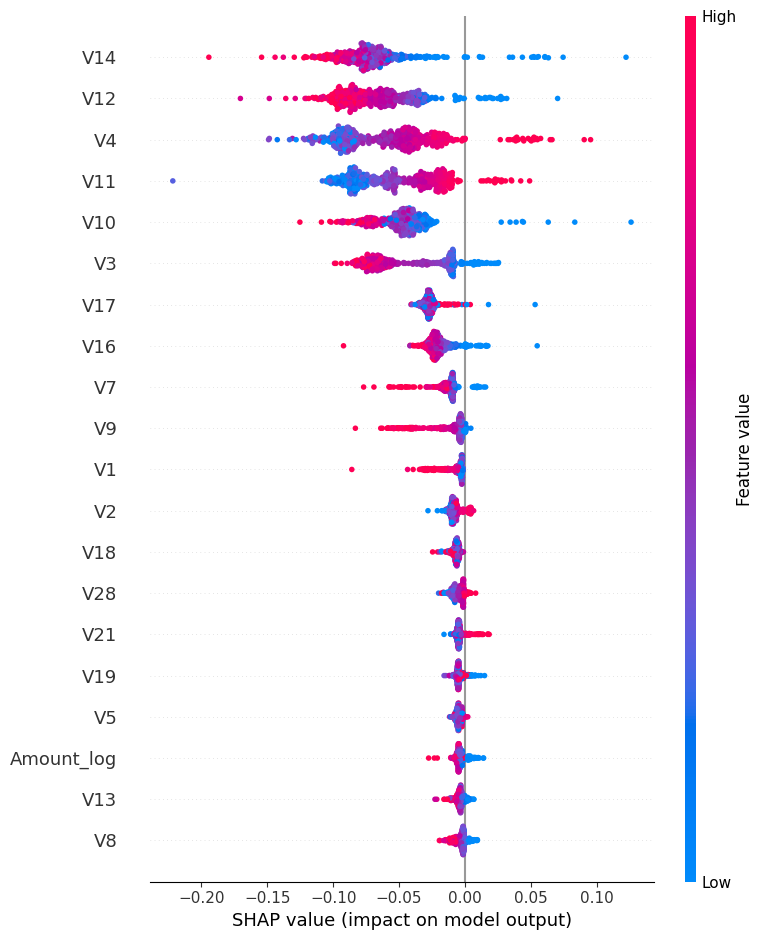

In [30]:
shap.summary_plot(
    shap_fraude,
    X_shap
)

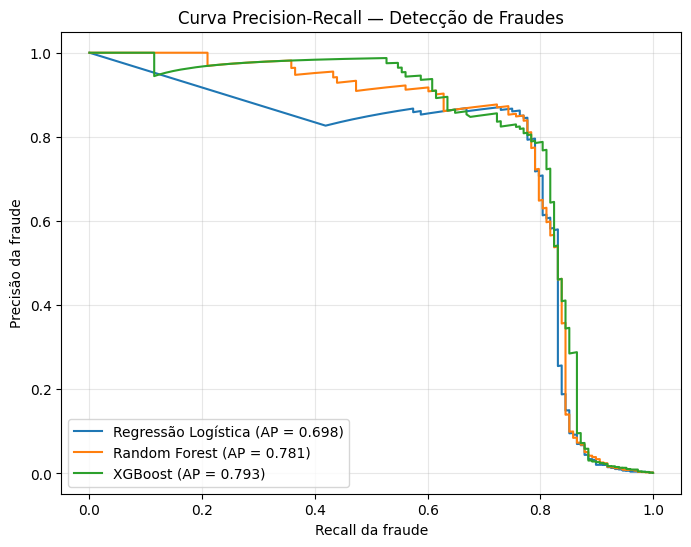

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Curva Precision-Recall para os três modelos
modelos = {
    "Regressão Logística": probabilidades,
    "Random Forest": probabilidades_rf,
    "XGBoost": probabilidades_xgb
}

plt.figure(figsize=(8, 6))

for nome, probs in modelos.items():
    precisao, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    plt.plot(recall, precisao, label=f"{nome} (AP = {ap:.3f})")

plt.xlabel("Recall da fraude")
plt.ylabel("Precisão da fraude")
plt.title("Curva Precision-Recall — Detecção de Fraudes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretabilidade do modelo com SHAP

Foi utilizada a biblioteca SHAP para interpretar as previsões do modelo Random Forest.

Foram gerados dois gráficos:

1. **Importância global das variáveis:** apresenta as variáveis com maior contribuição média para as previsões do modelo.
2. **Resumo SHAP (beeswarm):** mostra como os valores das variáveis influenciam as previsões para as transações analisadas.

A análise foi realizada em uma amostra de 500 transações do conjunto de teste. As variáveis `V1` a `V28` são componentes transformados por PCA, portanto seus significados individuais não podem ser interpretados diretamente sem informações adicionais.

**Limitação:** SHAP ajuda a compreender o comportamento do modelo, mas não comprova causalidade nem garante que as previsões estejam corretas.

In [32]:
# Probabilidades de fraude previstas pelo Random Forest
probabilidades_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Ajustar o limiar para 0.30
y_pred_rf_30 = (probabilidades_rf >= 0.30).astype(int)

# Avaliar o resultado
print("Random Forest — limiar 0.30")
print(classification_report(y_test, y_pred_rf_30, digits=4))

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred_rf_30))

Random Forest — limiar 0.30
              precision    recall  f1-score   support

           0     0.9997    0.9991    0.9994     85295
           1     0.6061    0.8108    0.6936       148

    accuracy                         0.9988     85443
   macro avg     0.8029    0.9049    0.8465     85443
weighted avg     0.9990    0.9988    0.9988     85443

Matriz de confusão:
[[85217    78]
 [   28   120]]


In [33]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Reduzir a classe majoritária apenas nos dados de treino
undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train, y_train
)

print("Distribuição original:")
print(y_train.value_counts())

print("\nDistribuição após undersampling:")
print(y_train_under.value_counts())

Distribuição original:
Class
0    199020
1       344
Name: count, dtype: int64

Distribuição após undersampling:
Class
0    344
1    344
Name: count, dtype: int64


In [34]:
modelo_rf_under = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_rf_under.fit(X_train_under, y_train_under)

y_pred_under = modelo_rf_under.predict(X_test)

print("Random Forest com undersampling")
print(classification_report(y_test, y_pred_under, digits=4))

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred_under))

Random Forest com undersampling
              precision    recall  f1-score   support

           0     0.9998    0.9816    0.9906     85295
           1     0.0759    0.8716    0.1396       148

    accuracy                         0.9814     85443
   macro avg     0.5378    0.9266    0.5651     85443
weighted avg     0.9982    0.9814    0.9891     85443

Matriz de confusão:
[[83724  1571]
 [   19   129]]


In [35]:
from imblearn.over_sampling import RandomOverSampler

oversampler = RandomOverSampler(random_state=42)

X_train_over, y_train_over = oversampler.fit_resample(
    X_train, y_train
)

print("Distribuição após oversampling:")
print(y_train_over.value_counts())

Distribuição após oversampling:
Class
0    199020
1    199020
Name: count, dtype: int64


In [36]:
modelo_rf_over = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_rf_over.fit(X_train_over, y_train_over)

y_pred_over = modelo_rf_over.predict(X_test)

print("Random Forest com oversampling")
print(classification_report(y_test, y_pred_over, digits=4))

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred_over))

Random Forest com oversampling
              precision    recall  f1-score   support

           0     0.9996    0.9995    0.9996     85295
           1     0.7375    0.7973    0.7662       148

    accuracy                         0.9992     85443
   macro avg     0.8686    0.8984    0.8829     85443
weighted avg     0.9992    0.9992    0.9992     85443

Matriz de confusão:
[[85253    42]
 [   30   118]]


### Experimentos de balanceamento de classes

Foram comparadas três abordagens usando Random Forest: conjunto de treino original, Random Undersampling e Random Oversampling. O conjunto de teste permaneceu inalterado, com 85.443 transações e 148 fraudes.

- **Original:** precisão de 83,82%, recall de 77,03% e F1-score de 80,28%.
- **Undersampling:** precisão de 7,59%, recall de 87,16% e F1-score de 13,96%.
- **Oversampling:** precisão de 73,75%, recall de 79,73% e F1-score de 76,62%.

O undersampling apresentou o maior recall, mas também o maior número de falsos positivos. O oversampling obteve melhor equilíbrio entre precisão e recall do que o undersampling, embora o modelo original tenha apresentado o maior F1-score e menos falsos positivos.

Os resultados mostram que o balanceamento não garante melhoria em todas as métricas. A escolha deve considerar os custos dos erros e o objetivo do sistema de detecção.